In [1]:
!pip install -q xgboost imbalanced-learn xlrd

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import glob
import numpy as np
import pandas as pd

SEED = 42
BASE = "/content/drive/MyDrive"

xls_files = glob.glob(f"{BASE}/default_of_credit_card_clients/**/*.xls", recursive=True)
print("Found:", xls_files)
df = pd.read_excel(xls_files[0], header=1)

df = df.rename(columns={"PAY_0": "PAY_1", "default payment next month": "default"})
df = df.drop(columns=["ID"])
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
df = pd.get_dummies(df, columns=["SEX", "EDUCATION", "MARRIAGE"], drop_first=True)

X = df.drop(columns=["default"])
y = df["default"]

train_idx = pd.read_csv(f"{BASE}/data/train_idx.csv").iloc[:, 0]
test_idx  = pd.read_csv(f"{BASE}/data/test_idx.csv").iloc[:, 0]
X_train, y_train = X.loc[train_idx], y.loc[train_idx]
X_test,  y_test  = X.loc[test_idx],  y.loc[test_idx]

assert len(X_train) == 24000 and len(X_test) == 6000
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Default rate  train: %.4f | test: %.4f" % (y_train.mean(), y_test.mean()))

Found: ['/content/drive/MyDrive/default_of_credit_card_clients/default of credit card clients.xls']
Train: (24000, 26) | Test: (6000, 26)
Default rate  train: 0.2212 | test: 0.2212


In [5]:
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_xgb(spw=1, **params):
    return XGBClassifier(subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                         scale_pos_weight=spw, random_state=SEED, n_jobs=-1, **params)

def evaluate(name, model, X_te, y_te, threshold=0.5):
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    return {"Experiment": name, "Threshold": round(threshold, 2),
            "Accuracy": round(accuracy_score(y_te, pred), 2),
            "Precision": round(precision_score(y_te, pred, zero_division=0), 2),
            "Recall": round(recall_score(y_te, pred), 2),
            "F1": round(f1_score(y_te, pred), 2),
            "ROC-AUC": round(roc_auc_score(y_te, proba), 2),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

grid = GridSearchCV(make_xgb(),
                    {"max_depth": [3, 5],
                     "learning_rate": [0.05, 0.1],
                     "n_estimators": [200, 400]},
                    scoring="roc_auc", cv=cv, n_jobs=1)
grid.fit(X_train, y_train)
best_params = grid.best_params_
print("Best params:", best_params)
print(pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "std_test_score"]]
      .sort_values("mean_test_score", ascending=False).to_string(index=False))

Best params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}
                                                      params  mean_test_score  std_test_score
{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}         0.783608        0.005967
{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 400}         0.782804        0.006827
{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}         0.782371        0.005867
 {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}         0.782293        0.006889
{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 400}         0.780085        0.006580
 {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400}         0.780081        0.008116
 {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}         0.778474        0.006719
 {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 400}         0.771095        0.007388


In [6]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(spw, 2))
results = []

# E1: Baseline
base = make_xgb(**best_params)
base.fit(X_train, y_train)
results.append(evaluate("E1 Baseline", base, X_test, y_test))

# E2: SMOTE
smote = Pipeline([("smote", SMOTE(random_state=SEED)),
                  ("clf", make_xgb(**best_params))])
smote.fit(X_train, y_train)
results.append(evaluate("E2 SMOTE", smote, X_test, y_test))

cw = make_xgb(spw=spw, **best_params)
cw.fit(X_train, y_train)
results.append(evaluate("E3 scale_pos_weight", cw, X_test, y_test))

oof = cross_val_predict(make_xgb(**best_params), X_train, y_train, cv=cv,
                        method="predict_proba")[:, 1]
thresholds = np.arange(0.10, 0.90, 0.01)
best_t = max(thresholds, key=lambda t: f1_score(y_train, (oof >= t).astype(int)))
print("Best threshold (CV on train, max F1):", round(best_t, 2))
results.append(evaluate("E4 Threshold tuning", base, X_test, y_test, threshold=best_t))

out = pd.DataFrame(results)
print(out.to_string(index=False))

scale_pos_weight: 3.52
Best threshold (CV on train, max F1): 0.31
         Experiment  Threshold  Accuracy  Precision  Recall   F1  ROC-AUC   TN  FP  FN  TP
        E1 Baseline       0.50      0.82       0.66    0.36 0.47     0.78 4428 245 850 477
           E2 SMOTE       0.50      0.77       0.48    0.51 0.49     0.75 3941 732 650 677
E3 scale_pos_weight       0.50      0.77       0.48    0.62 0.54     0.78 3768 905 503 824
E4 Threshold tuning       0.31      0.80       0.54    0.54 0.54     0.78 4075 598 616 711


In [7]:
scoring = ["recall", "precision", "f1", "roc_auc"]
rows = []
for name, model in [("E1 Baseline", make_xgb(**best_params)),
                    ("E2 SMOTE", Pipeline([("smote", SMOTE(random_state=SEED)),
                                           ("clf", make_xgb(**best_params))])),
                    ("E3 scale_pos_weight", make_xgb(spw=spw, **best_params))]:
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    row = {"Experiment": name}
    for m in scoring:
        row[m] = f"{s['test_' + m].mean():.2f} ± {s['test_' + m].std():.2f}"
    rows.append(row)
cv_out = pd.DataFrame(rows)
print(cv_out.to_string(index=False))

         Experiment      recall   precision          f1     roc_auc
        E1 Baseline 0.37 ± 0.01 0.67 ± 0.01 0.48 ± 0.01 0.78 ± 0.01
           E2 SMOTE 0.51 ± 0.01 0.49 ± 0.01 0.50 ± 0.01 0.75 ± 0.01
E3 scale_pos_weight 0.62 ± 0.01 0.48 ± 0.01 0.54 ± 0.01 0.78 ± 0.01


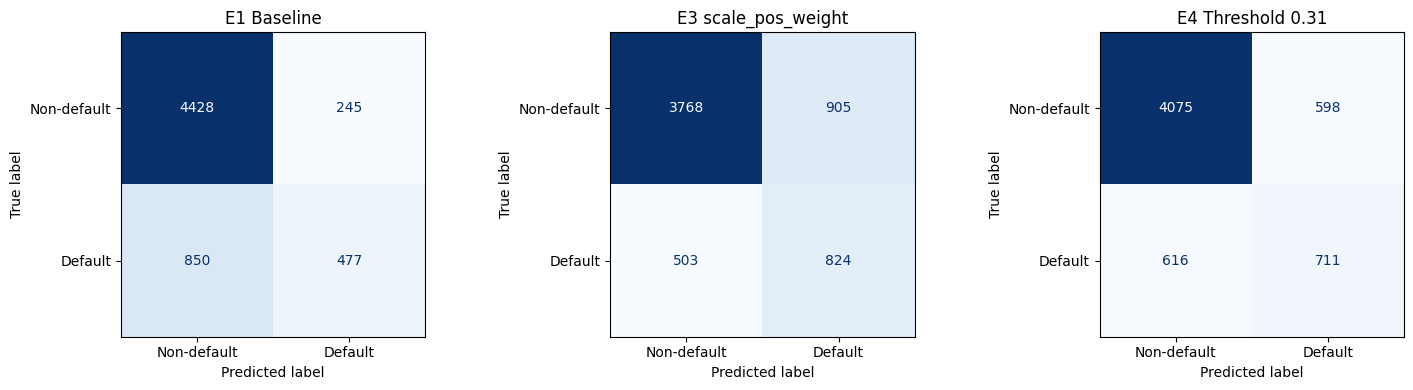

PAY_1        0.317
PAY_2        0.131
PAY_3        0.107
PAY_4        0.052
PAY_5        0.034
PAY_6        0.029
LIMIT_BAL    0.026
PAY_AMT1     0.024
PAY_AMT2     0.022
BILL_AMT1    0.021
dtype: float32


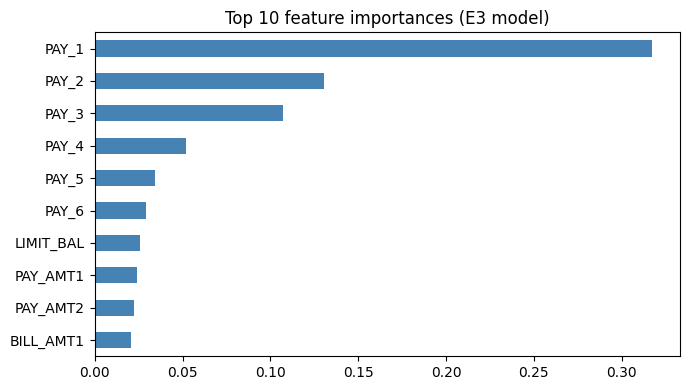

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model, t) in zip(axes, [("E1 Baseline", base, 0.5),
                                       ("E3 scale_pos_weight", cw, 0.5),
                                       (f"E4 Threshold {best_t:.2f}", base, best_t)]):
    pred = (model.predict_proba(X_test)[:, 1] >= t).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Non-default", "Default"],
        cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("pair_b_confusion_matrices.png", dpi=300)
plt.show()

imp = pd.Series(cw.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)
print(imp.round(3))
plt.figure(figsize=(7, 4))
imp[::-1].plot(kind="barh", color="steelblue")
plt.title("Top 10 feature importances (E3 model)")
plt.tight_layout()
plt.savefig("pair_b_feature_importance.png", dpi=300)
plt.show()

In [9]:
import os
RES = f"{BASE}/pair_b_results"
os.makedirs(RES, exist_ok=True)

out.to_csv(f"{RES}/pair_b_results.csv", index=False)
cv_out.to_csv(f"{RES}/pair_b_cv_results.csv", index=False)
imp.round(3).to_csv(f"{RES}/pair_b_top_importances.csv", header=["importance"])
!cp pair_b_confusion_matrices.png pair_b_feature_importance.png "{RES}/"
print("Saved to:", RES)

Saved to: /content/drive/MyDrive/pair_b_results
